In [1]:
#load the data from the csv file that we have saved.
import pandas as pd

train=pd.read_csv('train_data.csv')
train.head()

,id,click,hour,C1,banner_pos,site_id,site_domain,site_category,app_id,app_domain,...,C17,C18,C19,C20,C21,device_id_counts,device_ip_counts,hour_of_day,day_of_week,hourly_user_count
0,10007164336863914220,1,2014-10-21,1005,0,1fbe01fe,f3845767,28905ebd,ecad2386,7801e8d9,...,1722,0,35,-1,79,4124398,49,0,Tuesday,104941
1,10007197383452514432,0,2014-10-21,1005,0,1fbe01fe,f3845767,28905ebd,ecad2386,7801e8d9,...,1722,0,35,100084,79,4124398,37,0,Tuesday,104941
2,10007446479189647526,0,2014-10-21,1005,0,6ec06dbd,d262cf1e,f66779e6,ecad2386,7801e8d9,...,2271,0,687,100075,48,4124398,2,0,Tuesday,104941
3,10007768440836622373,0,2014-10-21,1005,0,85f751fd,c4e18dd6,50e219e0,e2a1ca37,2347f47a,...,1722,0,35,-1,79,28,9,0,Tuesday,104941
4,10010504760200486071,0,2014-10-21,1005,1,5ee41ff2,17d996e6,f028772b,ecad2386,7801e8d9,...,1863,3,39,100188,23,4124398,1,0,Tuesday,104941


In [2]:
# Separating numerical and categorical variables.

numerical = []
categorical = []

for col in (train.columns):
    if train[col].dtype == "object":
        categorical.append(col)
    else:
        numerical.append(col)
print("numerical columns = ",numerical)
print("\ncategorical columns = ",categorical)

numerical columns =  ['id', 'click', 'C1', 'banner_pos', 'device_type', 'device_conn_type', 'C14', 'C15', 'C16', 'C17', 'C18', 'C19', 'C20', 'C21', 'device_id_counts', 'device_ip_counts', 'hour_of_day', 'hourly_user_count']

categorical columns =  ['hour', 'site_id', 'site_domain', 'site_category', 'app_id', 'app_domain', 'app_category', 'device_id', 'device_ip', 'device_model', 'day_of_week']


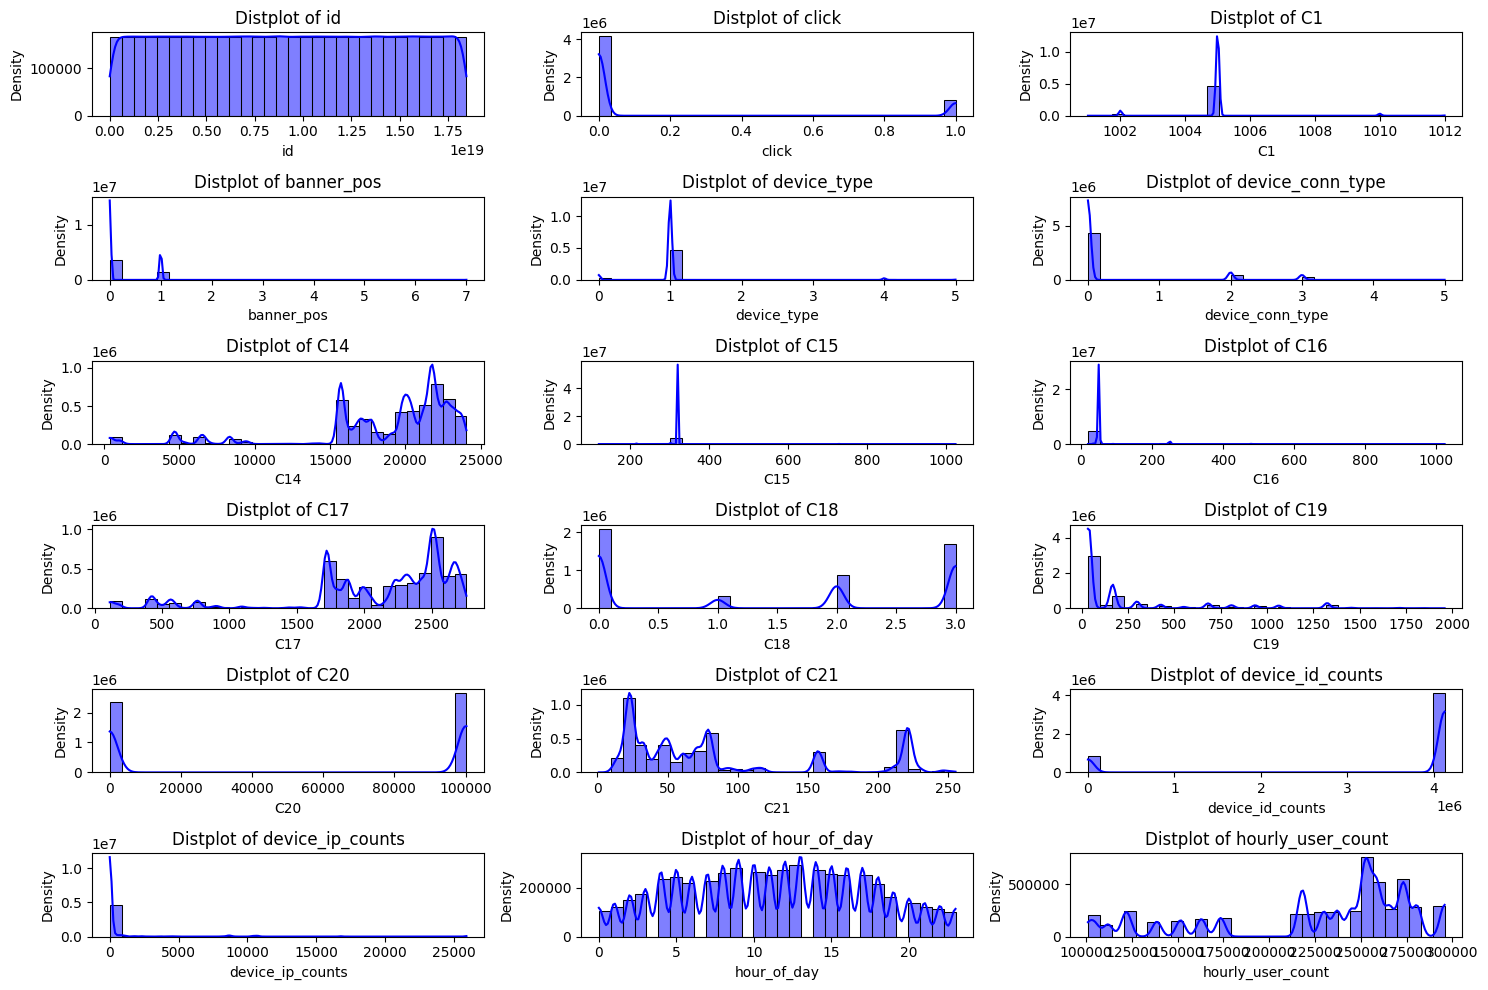

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# Set up the figure and axes for subplots
plt.figure(figsize=(15, 10))  # Adjust the figure size as needed

# Calculate number of rows and columns for the subplot grid
n_features = len(numerical)
n_cols = 3  # Number of columns
n_rows = (n_features + n_cols - 1) // n_cols  # Compute the number of rows

# Plot each histogram with a KDE (Kernel Density Estimate) curve
for i, feature in enumerate(numerical):
    plt.subplot(n_rows, n_cols, i + 1)
    sns.histplot(train[feature], bins=30, kde=True, color='blue')  # Add kde=True for the distplot-like effect
    plt.title(f'Distplot of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Density')

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()

Text(0.5, 1.05, 'Pearson correlation of Features')

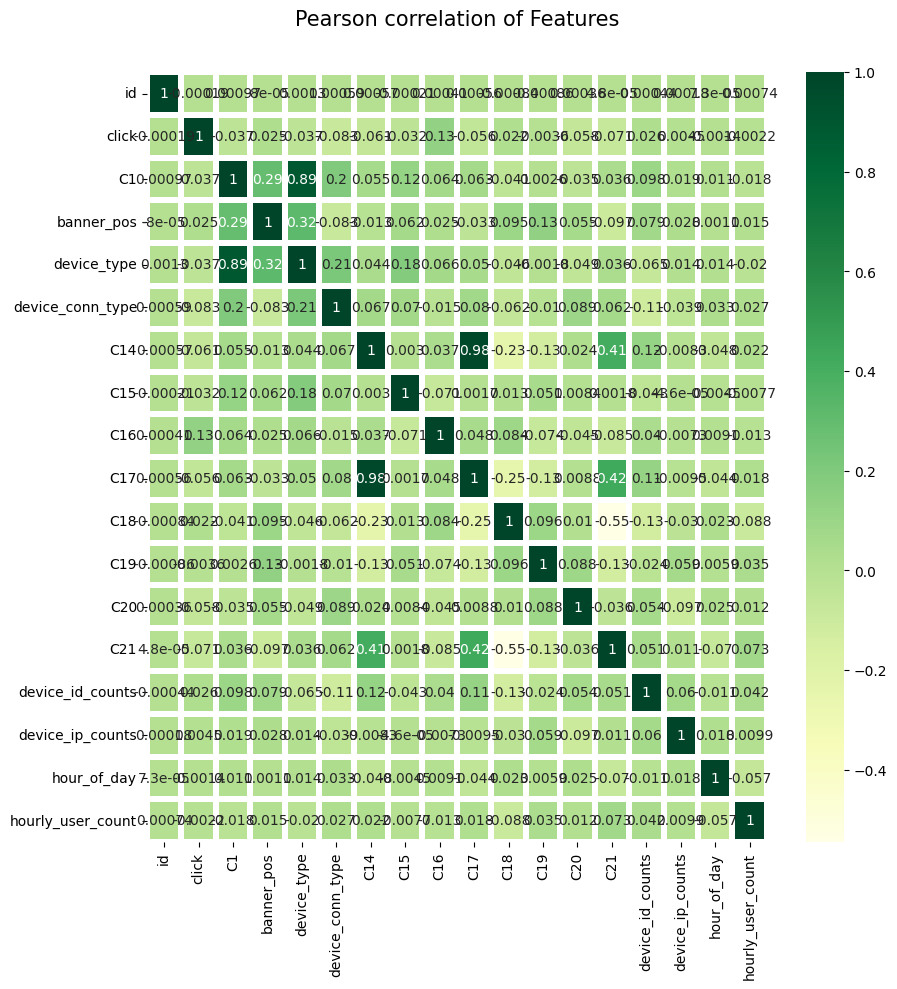

In [4]:
# Pearson correlation table to find the relationship with output with all numerical features. 

corr = train[numerical].corr()
f, ax = plt.subplots(figsize=(10,10))
sns.heatmap(corr, ax=ax, annot=True,linewidths=3,cmap='YlGn')
plt.title("Pearson correlation of Features", y=1.05, size=15)

->C14 and C17 are highly co-related, later will remove one of them after the base model.
->device type with C10 are highly co-related, later will remove one of them after the base model.
->Removing C20 anomalised column, since it have got nearly 47% of values with -1. As a categorical variable it's not expected to have values as -1.

In [5]:
C20_counts = train['C20'].value_counts()
print(C20_counts)

C20
-1         2344436
 100084     301764
 100148     221710
 100111     212534
 100077     195257
            ...   
 100027          1
 100134          1
 100198          1
 100006          1
 100246          1
Name: count, Length: 169, dtype: int64


In [6]:
train.drop(['C1','C14','C20'], axis=1, inplace=True)
train.columns

Index(['id', 'click', 'hour', 'banner_pos', 'site_id', 'site_domain',
       'site_category', 'app_id', 'app_domain', 'app_category', 'device_id',
       'device_ip', 'device_model', 'device_type', 'device_conn_type', 'C15',
       'C16', 'C17', 'C18', 'C19', 'C21', 'device_id_counts',
       'device_ip_counts', 'hour_of_day', 'day_of_week', 'hourly_user_count'],
      dtype='object')

In [7]:
train.drop(['id'], axis = 1, inplace = True)
train.rename(columns={'click': 'y'}, inplace=True, errors='raise')
train.columns

Index(['y', 'hour', 'banner_pos', 'site_id', 'site_domain', 'site_category',
       'app_id', 'app_domain', 'app_category', 'device_id', 'device_ip',
       'device_model', 'device_type', 'device_conn_type', 'C15', 'C16', 'C17',
       'C18', 'C19', 'C21', 'device_id_counts', 'device_ip_counts',
       'hour_of_day', 'day_of_week', 'hourly_user_count'],
      dtype='object')

In [8]:
# dataset is huge and running multiple algo will take time and resources might exhaust, 
# hence taking only 10% of the data for analysis.

sampled_data = train.sample(frac=0.1, random_state=42)
X = sampled_data.drop(['y'], axis=1)
y = sampled_data['y']

y
0    0.830234
1    0.169766
Name: proportion, dtype: float64




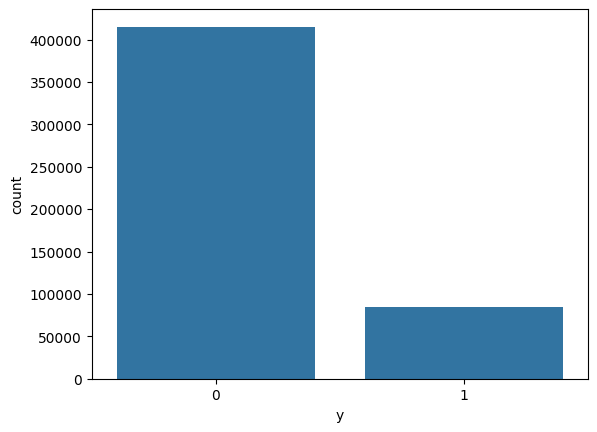

In [9]:
# After taking the sample of data, still the ratio of output remains same.

print(train.y.value_counts(normalize = True))
print("\n")
plt.figure()
sns.countplot(x=y)
plt.show()

In [10]:
import category_encoders as ce

target_encoder = ce.TargetEncoder()
X = target_encoder.fit_transform(X, y)
X.head()

,hour,banner_pos,site_id,site_domain,site_category,app_id,app_domain,app_category,device_id,device_ip,...,C16,C17,C18,C19,C21,device_id_counts,device_ip_counts,hour_of_day,day_of_week,hourly_user_count
3577888,0.151687,1,0.297121,0.259849,0.180709,0.199546,0.195796,0.200059,0.174516,0.147748,...,50,2647,2,35,23,4124398,4,10,0.160883,265609
4993932,0.157303,0,0.206728,0.206728,0.209179,0.199546,0.195796,0.200059,0.174516,0.147748,...,50,2545,0,431,221,4124398,1,23,0.176372,101108
4094900,0.156825,1,0.073834,0.073927,0.180709,0.199546,0.195796,0.200059,0.174516,0.147748,...,50,2227,0,935,48,4124398,3,4,0.158207,237072
4420497,0.137869,0,0.110379,0.110379,0.180709,0.199546,0.195796,0.200059,0.174516,0.161417,...,50,2526,0,167,221,4124398,645,19,0.158207,163007
634465,0.154014,0,0.117418,0.121454,0.127641,0.058499,0.136654,0.090129,0.147748,0.147748,...,50,2513,3,35,68,1,1,6,0.158207,218340


In [11]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

def evaluate_model(y_true, y_pred, model_name="Model"):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='binary')
    recall = recall_score(y_true, y_pred, average='binary')
    f1 = f1_score(y_true, y_pred, average='binary')
    
    metrics = {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    }
    
    return metrics


In [12]:
def plot_confusion_matrix(y_true, y_pred, model_name="Model"):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6,6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
    plt.title(f"Confusion Matrix for {model_name}")
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

In [13]:
# ROC-AUC calculation function
def roc_auc(y_true, y_proba, model_name="Model"):
    auc_value = roc_auc_score(y_true, y_proba)
    print(f"{model_name} ROC-AUC Score: {auc_value:.4f}")
    return auc_value

In [14]:
from sklearn.model_selection import cross_val_score, StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_curve, auc

def full_model_evaluation(model, X_train, y_train, X_test, y_test, cv_folds=5, results_df=None, model_name="Model"):
    """
    Evaluate model performance using cross-validation and test set.
    
    Parameters:
    - model: the machine learning model to evaluate
    - X_train: training features
    - y_train: training labels
    - X_test: testing features
    - y_test: testing labels
    - cv_folds: number of cross-validation folds (default is 5)
    - results_df: DataFrame to store the results (optional)
    - model_name: name of the model
    
    Returns:
    - Updated results DataFrame with evaluation metrics
    """
    # Stratified K-Folds cross-validator
    cv = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=42)
    
    # Perform cross-validation and compute accuracy across the folds
    cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy')
    
    print(f"{model_name} Cross-Validation Accuracy: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
    
    # Perform cross-validation predictions (useful for plotting ROC)
    y_train_pred_cv = cross_val_predict(model, X_train, y_train, cv=cv, method="predict")
    
    # Fit the model on the entire training set and evaluate on the test set
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    # Predict probabilities if available
    try:
        y_proba = model.predict_proba(X_test)[:, 1]
    except AttributeError:
        y_proba = None
    
    # Basic metrics
    metrics = evaluate_model(y_test, y_pred, model_name)
    
    # ROC-AUC if probabilities are provided
    if y_proba is not None:
        metrics["ROC-AUC"] = roc_auc_score(y_test, y_proba)
        print(f"{model_name} ROC-AUC Score: {metrics['ROC-AUC']:.4f}")
        
        # Plot ROC curve
        fpr, tpr, thresholds = roc_curve(y_test, y_proba)
        plt.figure(figsize=(6, 6))
        plt.plot(fpr, tpr, label=f'ROC curve (area = {metrics["ROC-AUC"]:.2f})')
        plt.plot([0, 1], [0, 1], 'k--')
        plt.xlim([0.0, 1.0])
        plt.ylim([0.0, 1.05])
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.title(f'Receiver Operating Characteristic for {model_name}')
        plt.legend(loc="lower right")
        plt.show()
    
    # Append the results to the DataFrame
    if results_df is None:
        results_df = pd.DataFrame(columns=["Model", "CV Accuracy", "Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"])
    
    metrics["Model"] = model_name
    metrics["CV Accuracy"] = cv_scores.mean()
    
    # Convert metrics to a DataFrame and concatenate it to results_df
    metrics_df = pd.DataFrame([metrics])
    results_df = pd.concat([results_df, metrics_df], ignore_index=True)
    
    # Confusion Matrix
    plot_confusion_matrix(y_test, y_pred, model_name)
    
    # Print classification report
    print(classification_report(y_test, y_pred))
    
    return results_df

Without SMOTE, 
Logistic Regression Cross-Validation Accuracy: 0.9286 ± 0.0008
Logistic Regression ROC-AUC Score: 0.9561

In [15]:
from imblearn.over_sampling import SMOTE

# Apply SMOTE
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

In [16]:
from collections import Counter
print('Original dataset shape  {}'.format(Counter(y)))
print('Resampled dataset shape {}'.format(Counter(y_resampled)))

Original dataset shape  Counter({0: 415077, 1: 84923})
Resampled dataset shape Counter({0: 415077, 1: 415077})


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, stratify=y_resampled, test_size= 0.2, random_state= 42)

In [18]:
from sklearn.preprocessing import MinMaxScaler

# Initialize MinMaxScaler
scaler = MinMaxScaler()

# Fit and transform on the training set
X_train_scaled = scaler.fit_transform(X_train)

# Transform the test set (only apply transform, no fit)
X_test_scaled = scaler.transform(X_test)

# Logistic Regression

Logistic Regression Cross-Validation Accuracy: 0.9028 ± 0.0010
Logistic Regression ROC-AUC Score: 0.9630


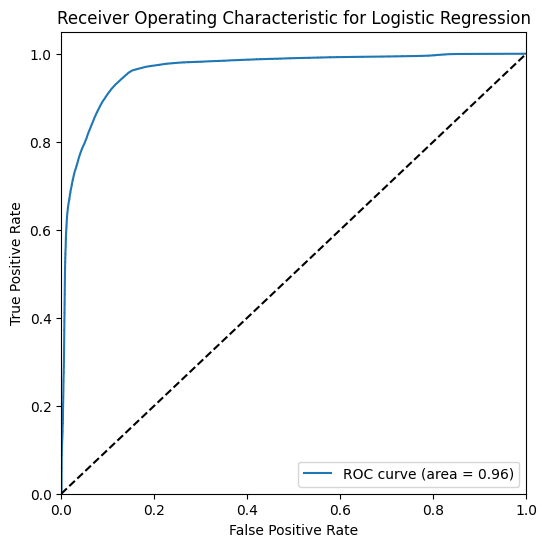

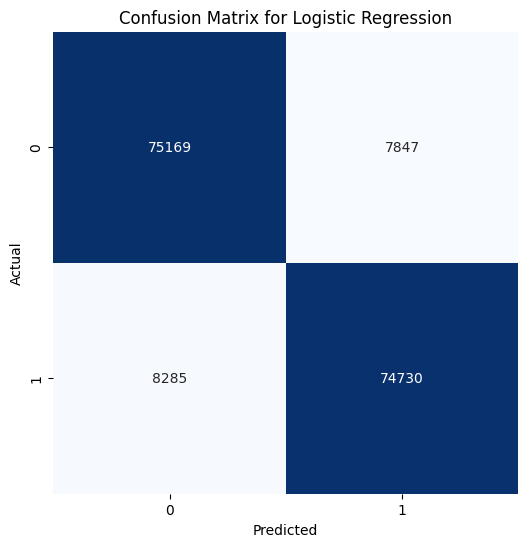

              precision    recall  f1-score   support

           0       0.90      0.91      0.90     83016
           1       0.90      0.90      0.90     83015

    accuracy                           0.90    166031
   macro avg       0.90      0.90      0.90    166031
weighted avg       0.90      0.90      0.90    166031



In [19]:
from sklearn.linear_model import LogisticRegression

model_lr = LogisticRegression()
model_lr.fit(X_train_scaled, y_train)

# Evaluate Logistic Regression and store the results
results_df = full_model_evaluation(model_lr, X_train_scaled, y_train, X_test_scaled, y_test, model_name="Logistic Regression", results_df=None)

# Gaussian Naive Bayes

GaussianNB Cross-Validation Accuracy: 0.8589 ± 0.0016
GaussianNB ROC-AUC Score: 0.9057


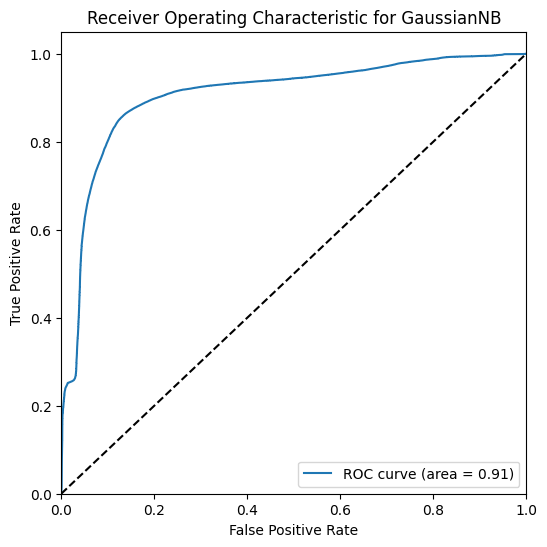

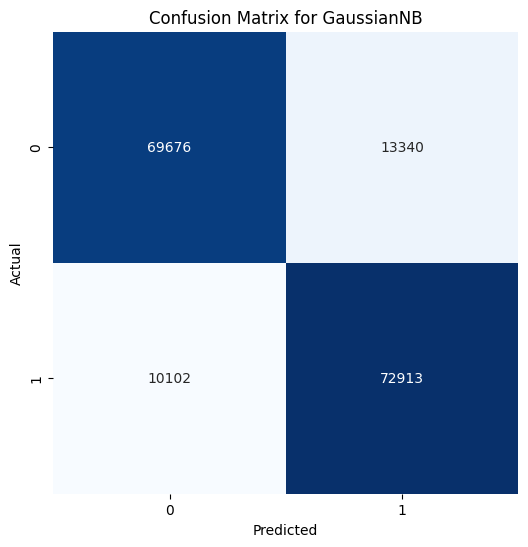

              precision    recall  f1-score   support

           0       0.87      0.84      0.86     83016
           1       0.85      0.88      0.86     83015

    accuracy                           0.86    166031
   macro avg       0.86      0.86      0.86    166031
weighted avg       0.86      0.86      0.86    166031



In [20]:
from sklearn.naive_bayes import GaussianNB

# Initialize the GaussianNB model
gnb_model = GaussianNB()

# Evaluate the GaussianNB model using the full_model_evaluation function
results_df = full_model_evaluation(gnb_model, X_train_scaled, y_train, X_test_scaled, y_test, model_name="GaussianNB")

# HistGradientBoostingClassifier

HistGradientBoosting Cross-Validation Accuracy: 0.9493 ± 0.0006
HistGradientBoosting ROC-AUC Score: 0.9928


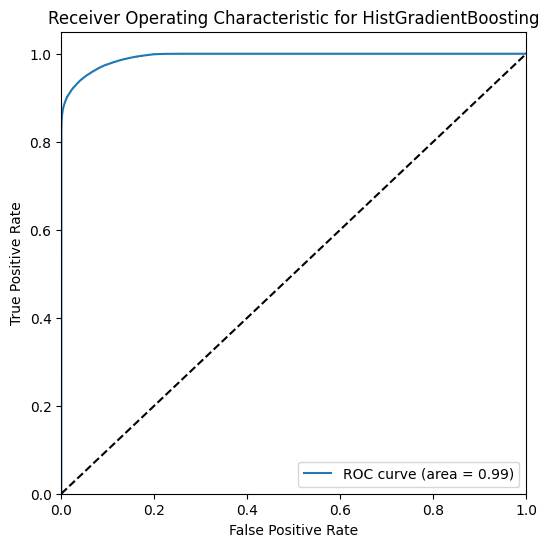

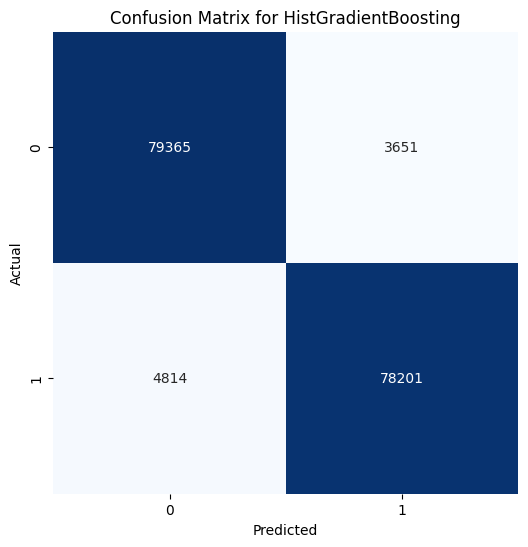

              precision    recall  f1-score   support

           0       0.94      0.96      0.95     83016
           1       0.96      0.94      0.95     83015

    accuracy                           0.95    166031
   macro avg       0.95      0.95      0.95    166031
weighted avg       0.95      0.95      0.95    166031



In [21]:
from sklearn.ensemble import HistGradientBoostingClassifier

# Define the HistGradientBoostingClassifier model
hist_gb = HistGradientBoostingClassifier(random_state=42)

# Evaluate the model using the full_model_evaluation function
results_df = full_model_evaluation(hist_gb, X_train_scaled, y_train, X_test_scaled, y_test, cv_folds=5, model_name="HistGradientBoosting")

# GAT

In [22]:
import torch
import torch.nn.functional as F
from torch_geometric.nn import GATConv
from torch_geometric.data import Data

In [23]:
# Move data to GPU if available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


In [24]:
# Convert features and labels to torch tensors and move them to the GPU
node_features = torch.tensor(X_train_scaled, dtype=torch.float).to(device)
labels = torch.tensor(y_train.values, dtype=torch.long).to(device)

'hour', 'banner_pos', 'site_id', 'site_domain', 'site_category', 'app_id', 'app_domain', 'app_category', 'device_id', 'device_ip', 'device_model', 'device_type', 'device_conn_type', 'C15', 'C16', 'C17', 'C18', 'C19', 'C21', 'device_id_counts', 'device_ip_counts', 'hour_of_day', 'day_of_week', 'hourly_user_count'

In [25]:
from sklearn.neighbors import NearestNeighbors
import numpy as np

def create_knn_edges(X, k=10):
    """
    Creates edges based on k-nearest neighbors for a given set of features.
    X: numpy array of features (node features)
    k: number of nearest neighbors to connect each node with
    """
    knn = NearestNeighbors(n_neighbors=k, metric='euclidean')
    knn.fit(X)
    
    # Get the k-nearest neighbors (returns distances and indices)
    distances, indices = knn.kneighbors(X)
    
    # Create edges (i, j) for each node with its k-nearest neighbors
    edges = []
    for i in range(indices.shape[0]):
        for j in indices[i]:
            if i != j:  # Avoid self-loops
                edges.append([i, j])
    
    return np.array(edges)

# Example usage with a batch of data
batch_size = 10000000  # Adjust batch size based on memory limits
edges = []

# Process data in batches
for start in range(0, len(X_train_scaled), batch_size):
    end = start + batch_size
    X_batch = X_train_scaled[start:end]
    
    # Create edges for the batch
    batch_edges = create_knn_edges(X_batch, k=10)
    
    # Add to the main edges list
    edges.append(batch_edges)

# Concatenate all edges from batches
edges = np.vstack(edges)
print(f"Total edges created: {edges.shape[0]}")


Total edges created: 5978572


In [26]:
# Convert edges to a PyTorch tensor (transpose to match PyG format)
edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous().to(device)

In [27]:
# Create graph data object
data = Data(x=node_features, edge_index=edge_index, y=labels).to(device)
print(data)

Data(x=[664123, 24], edge_index=[2, 5978572], y=[664123])


In [28]:
class GAT(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, heads=1, dropout=0.2):
        super(GAT, self).__init__()
        self.conv1 = GATConv(in_channels, hidden_channels, heads=heads, dropout=dropout)
        self.conv2 = GATConv(hidden_channels * heads, out_channels, heads=1, dropout=dropout)
        
    def forward(self, data):
        x, edge_index = data.x, data.edge_index

        # First GAT layer + activation (ReLU)
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, training=self.training)
        
        # Second GAT layer (output layer)
        x = self.conv2(x, edge_index)
        
        return F.log_softmax(x, dim=1)

# Instantiate the model
in_channels = X_train_scaled.shape[1]  # Number of features
hidden_channels = 16
out_channels = 2  # Binary classification
model_gat = GAT(in_channels, hidden_channels, out_channels).to(device)

print(model_gat)

GAT(
  (conv1): GATConv(24, 16, heads=1)
  (conv2): GATConv(16, 2, heads=1)
)


In [29]:
import torch.optim as optim

# Define loss and optimizer
criterion = torch.nn.CrossEntropyLoss()
optimizer = optim.Adam(model_gat.parameters(), lr=0.01)

def train():
    model_gat.train()
    optimizer.zero_grad()
    out = model_gat(data)
    loss = criterion(out, data.y)
    loss.backward()
    optimizer.step()
    return loss.item()

# Training loop
for epoch in range(200):  # Adjust epochs as needed
    loss = train()
    if epoch % 10 == 0:
        print(f'Epoch {epoch}, Loss: {loss:.4f}')

Epoch 0, Loss: 0.7093
Epoch 10, Loss: 0.6624
Epoch 20, Loss: 0.6296
Epoch 30, Loss: 0.5880
Epoch 40, Loss: 0.5489
Epoch 50, Loss: 0.5054
Epoch 60, Loss: 0.4583
Epoch 70, Loss: 0.4180
Epoch 80, Loss: 0.3846
Epoch 90, Loss: 0.3617
Epoch 100, Loss: 0.3436
Epoch 110, Loss: 0.3313
Epoch 120, Loss: 0.3202
Epoch 130, Loss: 0.3112
Epoch 140, Loss: 0.3041
Epoch 150, Loss: 0.2989
Epoch 160, Loss: 0.2942
Epoch 170, Loss: 0.2899
Epoch 180, Loss: 0.2865
Epoch 190, Loss: 0.2830


ROC-AUC Score: 0.9631


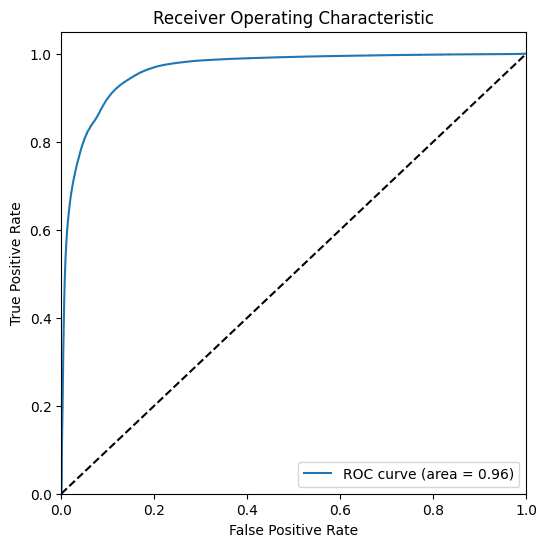


Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.89      0.90    332061
           1       0.89      0.91      0.90    332062

    accuracy                           0.90    664123
   macro avg       0.90      0.90      0.90    664123
weighted avg       0.90      0.90      0.90    664123



In [30]:
def evaluate_gat_model(model, data):
    """
    Evaluate the GAT model's performance and calculate key metrics.
    
    Parameters:
    - model: the trained GAT model
    - data: the graph data (should contain features, edges, and labels)
    
    Returns:
    - Prints evaluation metrics: Accuracy, ROC-AUC, Precision, Recall, F1 Score
    - Plots the ROC curve
    """
    model.eval()  # Set model to evaluation mode
    with torch.no_grad():
        # Get predictions from the GAT model
        out = model(data)
        
        # Convert the logits to predicted class labels
        _, y_pred = out.max(dim=1)
        
        # Get the actual labels
        y_true = data.y.cpu().numpy()
        y_pred = y_pred.cpu().numpy()
        
        # If using softmax for probability outputs
        y_proba = out.softmax(dim=1)[:, 1].cpu().numpy()
        
        # Calculate ROC-AUC score
        roc_auc = roc_auc_score(y_true, y_proba)
        print(f"ROC-AUC Score: {roc_auc:.4f}")
        
        # Plot the ROC curve
        fpr, tpr, thresholds = roc_curve(y_true, y_proba)
        plt.figure(figsize=(6, 6))
        plt.plot(fpr, tpr, label=f'ROC curve (area = {roc_auc:.2f})')
        plt.plot([0, 1], [0, 1], 'k--')
        plt.xlim([0.0, 1.0])
        plt.ylim([0.0, 1.05])
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.title('Receiver Operating Characteristic')
        plt.legend(loc="lower right")
        plt.show()
        
        # Print classification report
        print("\nClassification Report:")
        print(classification_report(y_true, y_pred))

# Example usage:
evaluate_gat_model(model_gat, data)

# XAI Implementation

In [31]:
import shap

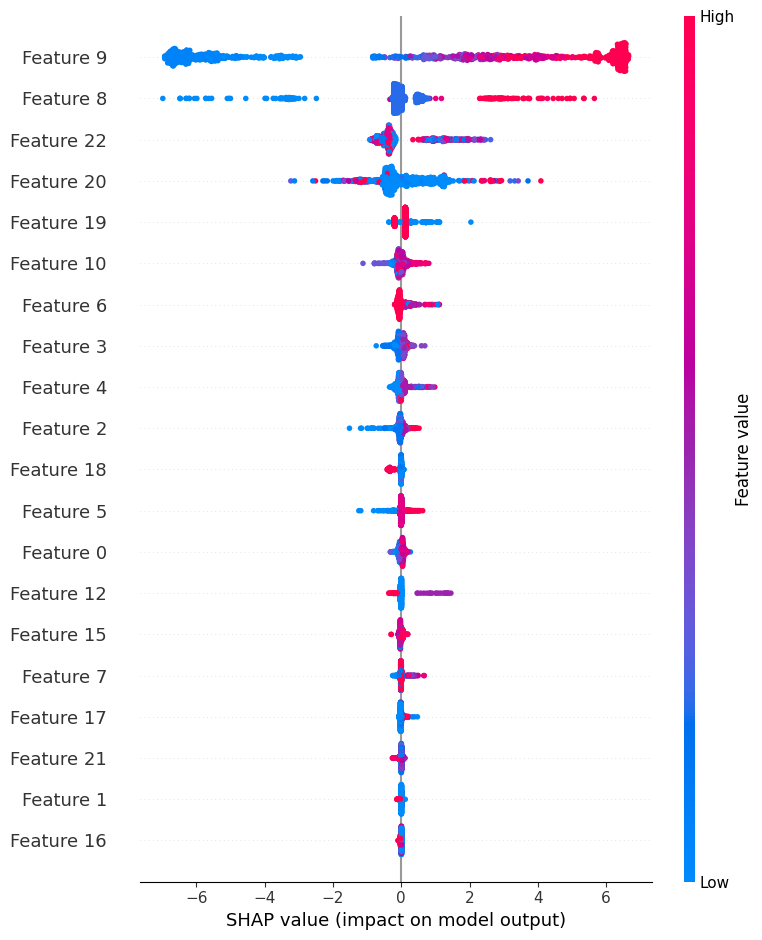

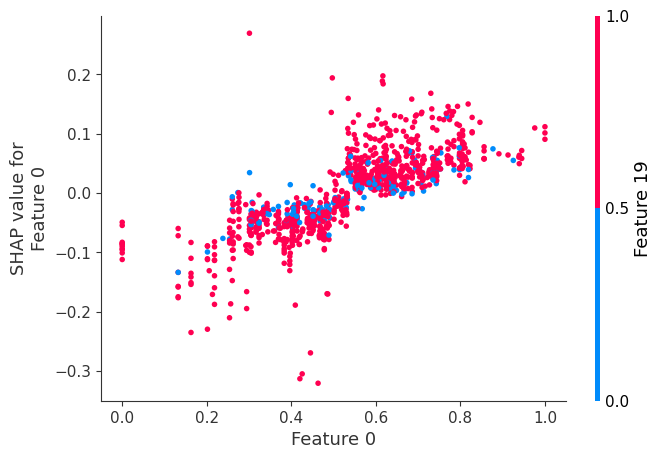

In [32]:
# Initialize SHAP TreeExplainer for HistGB
explainer = shap.TreeExplainer(hist_gb)

# 3. Select a sample for SHAP explanations (this step is optional but can help with large datasets)
sample_size = 1000  # Adjust sample size based on your system's memory
X_test_sample = X_test_scaled[:sample_size]

# 4. Calculate SHAP values for the test data
shap_values = explainer.shap_values(X_test_sample)

# 5. Plot SHAP summary plot
shap.summary_plot(shap_values, X_test_sample)
